# Customer Retention Intelligence
## Customer Churn Prediction & Retention Recommendation Mini-Project

### Project workflow
1. Load 100 customer records.
2. Prepare customer information and historical churn labels.
3. Train a Logistic Regression model.
4. Predict churn probability for each customer.
5. Assign Low, Medium, or High churn risk.
6. Recommend a suitable retention offer, such as a discount, contract benefit, or support package.
7. Display and save the final customer-wise results.
8. Compare classification models and review evaluation metrics.


## 1. Import libraries

In [1]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from IPython.display import display, HTML
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve
)


## 2. Load the dataset

In [2]:
df = pd.read_csv("Customer_Retention_100_Records.csv")

print("Total customers:", len(df))
print("Total columns:", len(df.columns))

# Display every customer record in a scrollable table (no hidden rows).
display(HTML(
    df.to_html(index=False, border=0)
))

Total customers: 100
Total columns: 15


Customer_ID,SeniorCitizen,Partner,Dependents,tenure,InternetService,OnlineSecurity,OnlineBackup,TechSupport,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1,0,No,No,32,Fiber optic,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),108.15,3432.90,Yes
2,0,No,No,22,Fiber optic,Yes,No,No,Month-to-month,Yes,Bank transfer (automatic),101.35,2317.10,Yes
3,0,No,No,29,No,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.80,572.20,No
4,0,Yes,No,20,Fiber optic,No,No,No,Month-to-month,Yes,Mailed check,89.00,1820.45,Yes
5,0,No,No,13,Fiber optic,No,Yes,No,Month-to-month,Yes,Electronic check,79.80,973.45,Yes
6,0,No,No,2,DSL,No,Yes,No,Month-to-month,No,Mailed check,49.20,103.70,No
7,0,No,No,13,Fiber optic,No,Yes,No,One year,Yes,Mailed check,74.65,966.25,No
8,0,No,No,2,No,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.25,36.80,No
9,0,No,No,35,No,No internet service,No internet service,No internet service,One year,No,Mailed check,21.10,741.00,No
10,0,Yes,Yes,72,Fiber optic,Yes,Yes,Yes,Two year,No,Bank transfer (automatic),114.45,8100.55,No


## 3. Prepare customer data

`Customer_ID` identifies each customer and is not used for prediction. `Churn` is the historical target label: Yes means the customer previously left, and No means the customer stayed.

In [3]:
# Ensure numeric columns have numeric values.
for column in ["tenure", "MonthlyCharges", "TotalCharges"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

customer_ids = df["Customer_ID"]
actual_churn = df["Churn"].map({"Yes": 1, "No": 0})

X = df.drop(columns=["Customer_ID", "Churn"])
y = actual_churn

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "bool"]).columns.tolist()

print("Customer records ready:", len(X))
print("Customer information fields:", len(X.columns))

Customer records ready: 100
Customer information fields: 13


## 4. Prepare data for the prediction model

In [4]:
numeric_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

## 5. Train the churn prediction model

In [5]:
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

model.fit(X, y)

print("Customer churn prediction model is ready.")

Customer churn prediction model is ready.


## 6. Predict churn probability for every customer

The model estimates the probability that each customer may churn. These probabilities are estimates, not guarantees.

In [6]:
# Use out-of-fold predictions so each customer's own label is not used
# to train the model that generates that customer's probability.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

churn_probabilities = cross_val_predict(
    model, X, y, cv=cv, method="predict_proba"
)[:, 1]

results = pd.DataFrame({
    "Customer_ID": customer_ids,
    "Actual_Churn": df["Churn"],
    "Churn_Probability": churn_probabilities
})

results["Predicted_Churn"] = results["Churn_Probability"].apply(
    lambda p: "Yes" if p >= 0.50 else "No"
)

results["Risk_Level"] = results["Churn_Probability"].apply(
    lambda p: "High" if p >= 0.60 else ("Medium" if p >= 0.30 else "Low")
)

# Display all customers; the HTML output is scrollable and does not truncate rows.
display(HTML(
    results.round({"Churn_Probability": 3}).to_html(index=False, border=0)
))

Customer_ID,Actual_Churn,Churn_Probability,Predicted_Churn,Risk_Level
1,Yes,0.492,No,Medium
2,Yes,0.757,Yes,High
3,No,0.031,No,Low
4,Yes,0.473,No,Medium
5,Yes,0.809,Yes,High
6,No,0.448,No,Medium
7,No,0.725,Yes,High
8,No,0.305,No,Medium
9,No,0.042,No,Low
10,No,0.069,No,Low


## 7. Generate personalized retention recommendations

The rules below suggest practical actions based on predicted churn risk and each customer's profile. The discount offers are illustrative recommendations only; they are not automatically applied. All 100 customers are shown in a scrollable table.

In [7]:
def recommend_offer(customer, risk):
    offers = []

    # Offer based on predicted churn risk.
    if risk == "High":
        offers.append("15% monthly bill discount for 3 months")
        offers.append("Personal retention call within 24 hours")
    elif risk == "Medium":
        offers.append("10% monthly bill discount for 2 months")
        offers.append("Offer a suitable plan review")
    else:
        offers.append("5% loyalty discount on next bill")
        offers.append("Send a loyalty appreciation message")

    # Additional offers based on customer profile.
    if customer["Contract"] == "Month-to-month":
        offers.append("Special discount for switching to a 1-year contract")

    if customer["TechSupport"] == "No":
        offers.append("One month of free technical support")

    if customer["OnlineSecurity"] == "No":
        offers.append("One month of free online security")

    if customer["MonthlyCharges"] >= df["MonthlyCharges"].median():
        offers.append("Review plan for a lower-cost package")

    return " | ".join(dict.fromkeys(offers))


customer_lookup = df.set_index("Customer_ID")

results["Recommended_Offer"] = results.apply(
    lambda row: recommend_offer(
        customer_lookup.loc[row["Customer_ID"]],
        row["Risk_Level"]
    ),
    axis=1
)

recommendation_output = results[[
    "Customer_ID",
    "Churn_Probability",
    "Risk_Level",
    "Recommended_Offer"
]].copy()

recommendation_output["Churn_Probability"] = (
    recommendation_output["Churn_Probability"].round(3)
)

print("Personalized recommendations generated:", len(recommendation_output))

# Render every customer row in a scrollable HTML table.
# Unlike the default Pandas display, this does not replace middle rows with "...".
display(HTML(
    '<div style="max-height:600px; overflow:auto; border:1px solid #ddd;">'
    + recommendation_output.to_html(index=False, border=0)
    + '</div>'
))

Personalized recommendations generated: 100


Customer_ID,Churn_Probability,Risk_Level,Recommended_Offer
1,0.492,Medium,10% monthly bill discount for 2 months | Offer a suitable plan review | Special discount for switching to a 1-year contract | Review plan for a lower-cost package
2,0.757,High,15% monthly bill discount for 3 months | Personal retention call within 24 hours | Special discount for switching to a 1-year contract | One month of free technical support | Review plan for a lower-cost package
3,0.031,Low,5% loyalty discount on next bill | Send a loyalty appreciation message
4,0.473,Medium,10% monthly bill discount for 2 months | Offer a suitable plan review | Special discount for switching to a 1-year contract | One month of free technical support | One month of free online security | Review plan for a lower-cost package
5,0.809,High,15% monthly bill discount for 3 months | Personal retention call within 24 hours | Special discount for switching to a 1-year contract | One month of free technical support | One month of free online security | Review plan for a lower-cost package
6,0.448,Medium,10% monthly bill discount for 2 months | Offer a suitable plan review | Special discount for switching to a 1-year contract | One month of free technical support | One month of free online security
7,0.725,High,15% monthly bill discount for 3 months | Personal retention call within 24 hours | One month of free technical support | One month of free online security | Review plan for a lower-cost package
8,0.305,Medium,10% monthly bill discount for 2 months | Offer a suitable plan review | Special discount for switching to a 1-year contract
9,0.042,Low,5% loyalty discount on next bill | Send a loyalty appreciation message
10,0.069,Low,5% loyalty discount on next bill | Send a loyalty appreciation message | Review plan for a lower-cost package


## 8. View the final customer-wise project output

In [8]:
final_output = results[[
    "Customer_ID",
    "Actual_Churn",
    "Predicted_Churn",
    "Churn_Probability",
    "Risk_Level",
    "Recommended_Offer"
]].copy()

final_output["Churn_Probability"] = (
    final_output["Churn_Probability"] * 100
).round(1).astype(str) + "%"

final_output = final_output.sort_values("Customer_ID")

# Display all 100 rows in a scrollable table without ellipses.
display(HTML(
    final_output.to_html(index=False, border=0)
))

Customer_ID,Actual_Churn,Predicted_Churn,Churn_Probability,Risk_Level,Recommended_Offer
1,Yes,No,49.2%,Medium,10% monthly bill discount for 2 months | Offer a suitable plan review | Special discount for switching to a 1-year contract | Review plan for a lower-cost package
2,Yes,Yes,75.7%,High,15% monthly bill discount for 3 months | Personal retention call within 24 hours | Special discount for switching to a 1-year contract | One month of free technical support | Review plan for a lower-cost package
3,No,No,3.1%,Low,5% loyalty discount on next bill | Send a loyalty appreciation message
4,Yes,No,47.3%,Medium,10% monthly bill discount for 2 months | Offer a suitable plan review | Special discount for switching to a 1-year contract | One month of free technical support | One month of free online security | Review plan for a lower-cost package
5,Yes,Yes,80.9%,High,15% monthly bill discount for 3 months | Personal retention call within 24 hours | Special discount for switching to a 1-year contract | One month of free technical support | One month of free online security | Review plan for a lower-cost package
6,No,No,44.8%,Medium,10% monthly bill discount for 2 months | Offer a suitable plan review | Special discount for switching to a 1-year contract | One month of free technical support | One month of free online security
7,No,Yes,72.5%,High,15% monthly bill discount for 3 months | Personal retention call within 24 hours | One month of free technical support | One month of free online security | Review plan for a lower-cost package
8,No,No,30.5%,Medium,10% monthly bill discount for 2 months | Offer a suitable plan review | Special discount for switching to a 1-year contract
9,No,No,4.2%,Low,5% loyalty discount on next bill | Send a loyalty appreciation message
10,No,No,6.9%,Low,5% loyalty discount on next bill | Send a loyalty appreciation message | Review plan for a lower-cost package


## 9. Save the final results

In [9]:
# 9. Save the final results

final_output.to_csv("Customer_Retention_Final_Results.csv", index=False)
print("Saved: Customer_Retention_Final_Results.csv")
print("Rows saved:", len(final_output))

Saved: Customer_Retention_Final_Results.csv
Rows saved: 100


## 10. Customer Retention Data Visualization

This section presents the customer data using different chart types. The charts summarize historical churn, predicted risk, customer tenure, monthly charges, and contract patterns.

**Note:** These charts describe the 100-customer sample. They are descriptive visualizations, not model evaluation metrics.

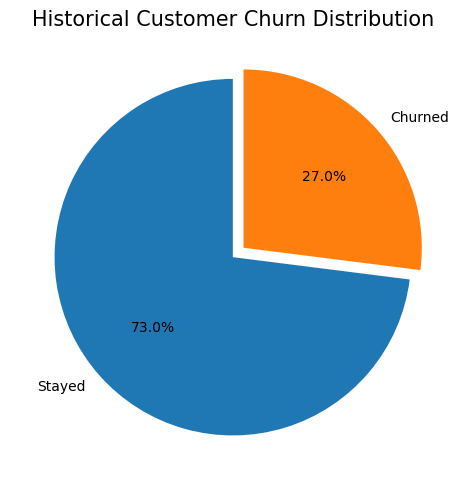

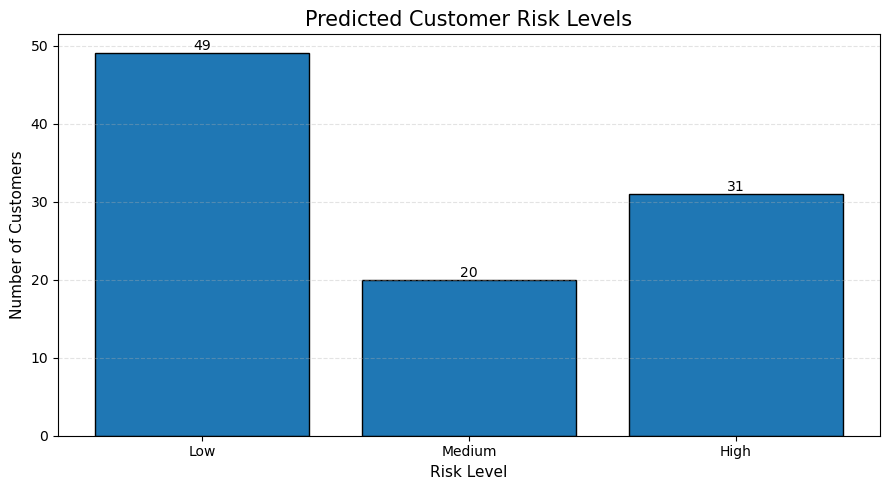

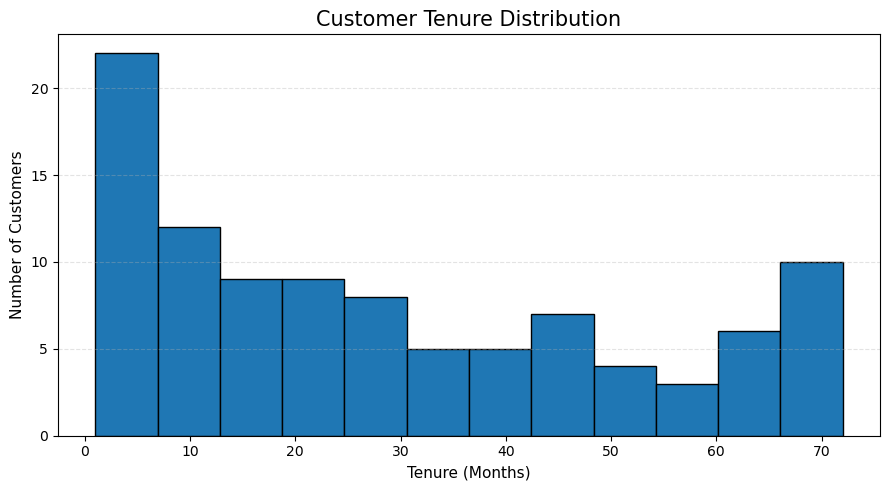

C:\Users\vikra\AppData\Local\Temp\ipykernel_34244\1018925400.py:85: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


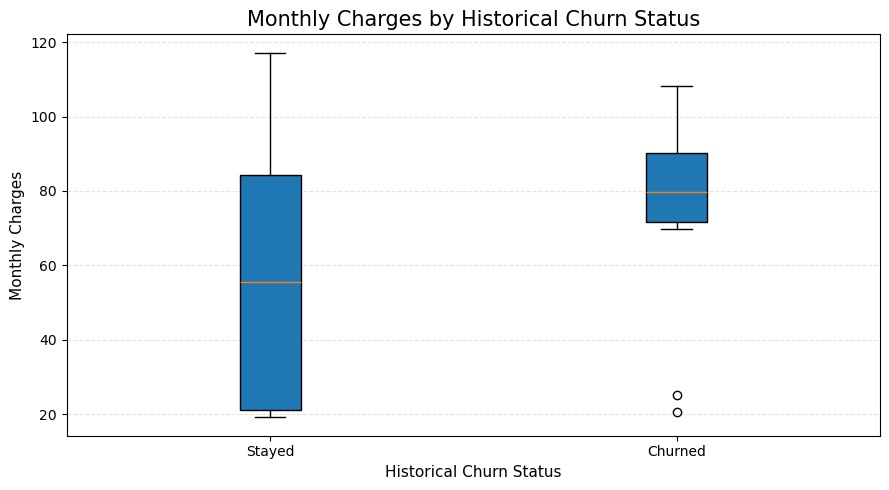

<Figure size 900x500 with 0 Axes>

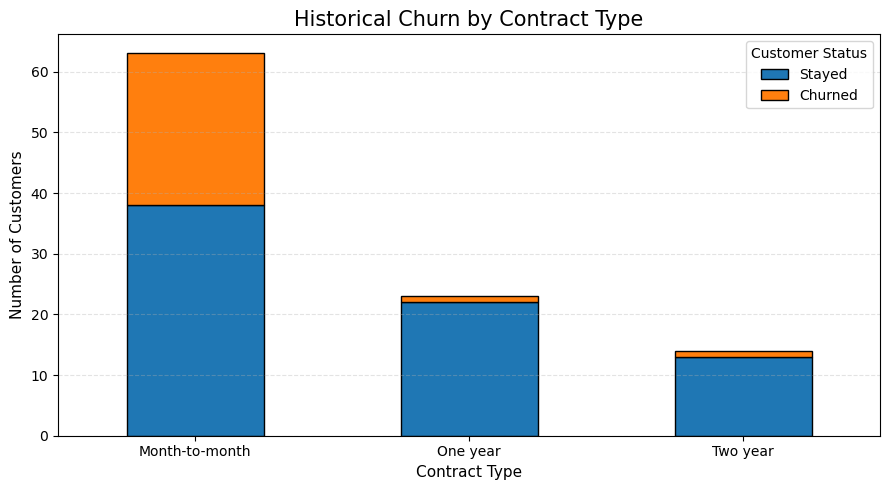

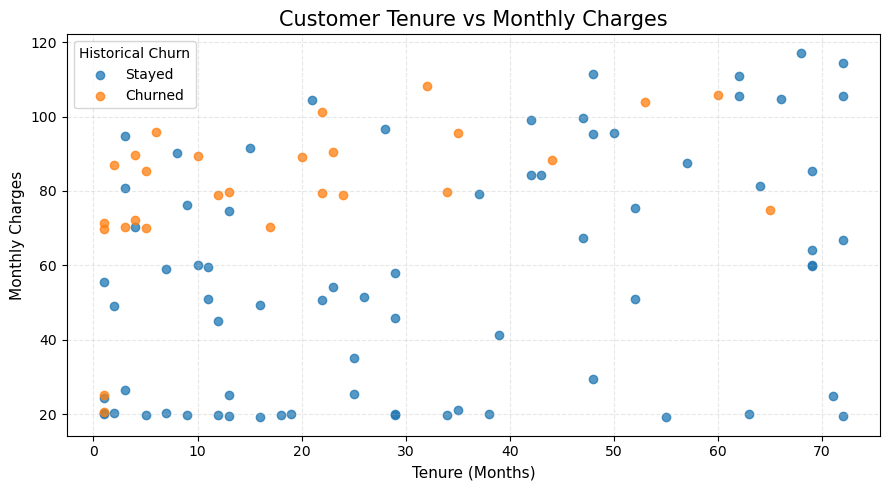

Visualization section completed successfully.


In [10]:
# 10. Customer Retention Data Visualization

# Prepare chart data
chart_df = df.copy()
chart_df["Churn"] = chart_df["Churn"].astype(str)
chart_df["tenure"] = pd.to_numeric(chart_df["tenure"], errors="coerce")
chart_df["MonthlyCharges"] = pd.to_numeric(
    chart_df["MonthlyCharges"], errors="coerce"
)

# Consistent chart formatting
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10
})

# Chart 1: Historical churn distribution
churn_counts = chart_df["Churn"].value_counts().reindex(
    ["No", "Yes"], fill_value=0
)

plt.figure()
plt.pie(
    churn_counts,
    labels=["Stayed", "Churned"],
    autopct="%1.1f%%",
    startangle=90,
    explode=(0, 0.08)
)
plt.title("Historical Customer Churn Distribution")
plt.tight_layout()
plt.show()

# Chart 2: Predicted customer risk distribution
risk_order = ["Low", "Medium", "High"]
risk_counts = results["Risk_Level"].value_counts().reindex(
    risk_order, fill_value=0
)

plt.figure()
bars = plt.bar(
    risk_counts.index,
    risk_counts.values,
    edgecolor="black"
)
plt.title("Predicted Customer Risk Levels")
plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")
plt.grid(axis="y", linestyle="--", alpha=0.35)
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height())}",
        ha="center",
        va="bottom"
    )
plt.tight_layout()
plt.show()

# Chart 3: Customer tenure distribution
plt.figure()
plt.hist(
    chart_df["tenure"].dropna(),
    bins=12,
    edgecolor="black"
)
plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

# Chart 4: Monthly charges by historical churn status
charge_groups = [
    chart_df.loc[chart_df["Churn"] == "No", "MonthlyCharges"].dropna(),
    chart_df.loc[chart_df["Churn"] == "Yes", "MonthlyCharges"].dropna()
]

plt.figure()
plt.boxplot(
    charge_groups,
    labels=["Stayed", "Churned"],
    patch_artist=True
)
plt.title("Monthly Charges by Historical Churn Status")
plt.xlabel("Historical Churn Status")
plt.ylabel("Monthly Charges")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

# Chart 5: Contract type distribution by historical churn
contract_churn = pd.crosstab(
    chart_df["Contract"],
    chart_df["Churn"]
).reindex(columns=["No", "Yes"], fill_value=0)

plt.figure()
contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    edgecolor="black"
)
plt.title("Historical Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(["Stayed", "Churned"], title="Customer Status")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()

# Chart 6: Tenure versus monthly charges, grouped by historical churn
plt.figure()
for status, label in [("No", "Stayed"), ("Yes", "Churned")]:
    subset = chart_df[chart_df["Churn"] == status]
    plt.scatter(
        subset["tenure"],
        subset["MonthlyCharges"],
        alpha=0.75,
        label=label
    )

plt.title("Customer Tenure vs Monthly Charges")
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.legend(title="Historical Churn")
plt.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

print("Visualization section completed successfully.")

## 11. Model Evaluation and Comparison

This section compares Logistic Regression, Decision Tree, and Random Forest using **5-fold stratified cross-validation**. Predictions for each customer are generated by a fold model that did not train on that customer's row.

Metrics reported:
- **Accuracy:** overall proportion of correct predictions.
- **Precision:** among customers predicted to churn, the proportion who actually churned.
- **Recall:** among customers who actually churned, the proportion detected by the model.
- **F1-score:** balance between precision and recall.
- **ROC-AUC:** ability to rank churned customers above non-churned customers.

Because this project uses a small 100-record sample, the scores are indicative and may vary with a different sample. They should not be treated as proof of production-level performance.

MODEL COMPARISON – 5-FOLD CROSS-VALIDATION


Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
Random Forest,0.79,0.594,0.704,0.644,0.807
Logistic Regression,0.74,0.514,0.667,0.581,0.792
Decision Tree,0.70,0.463,0.704,0.559,0.672


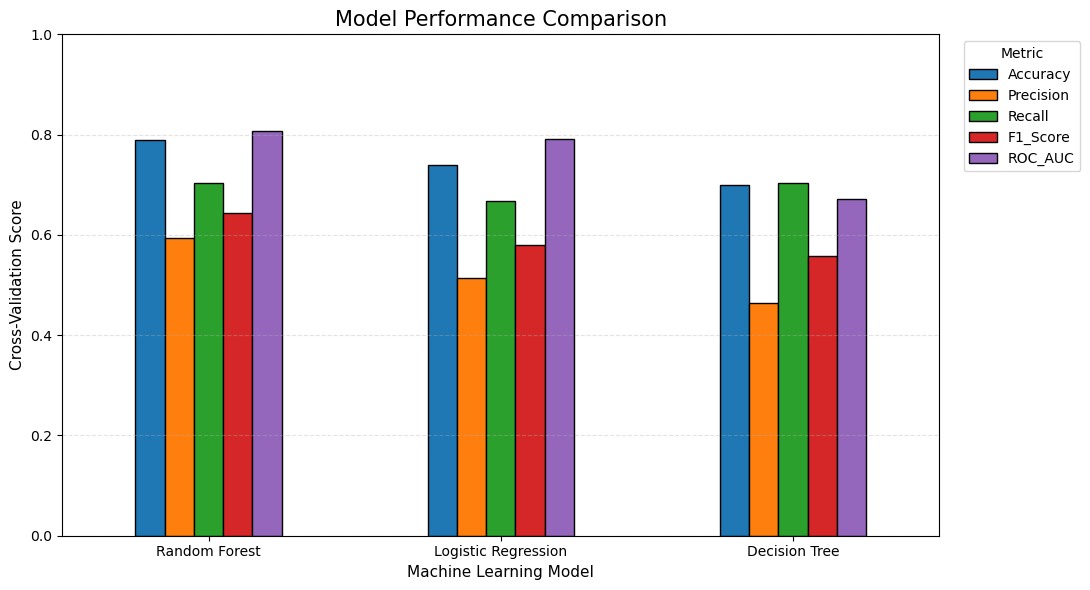

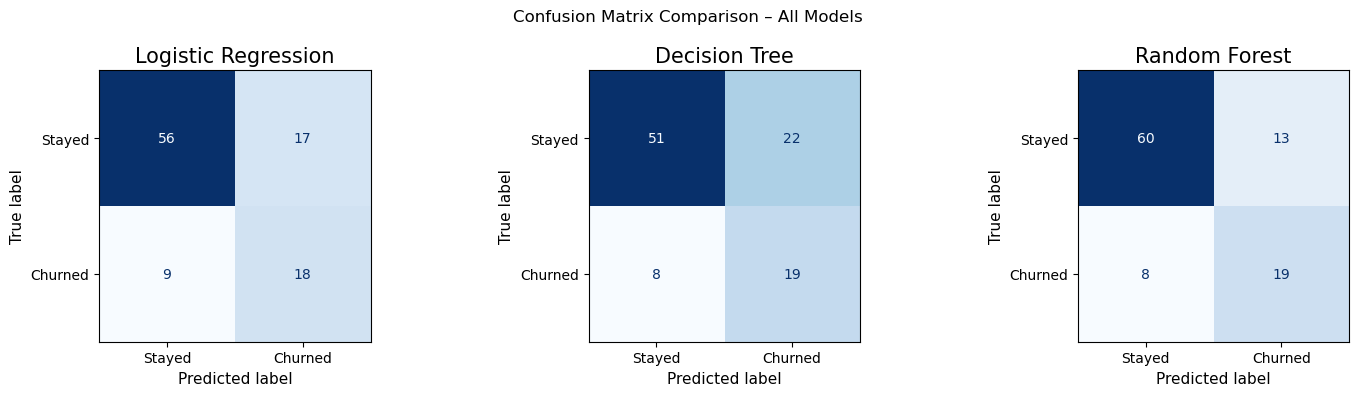

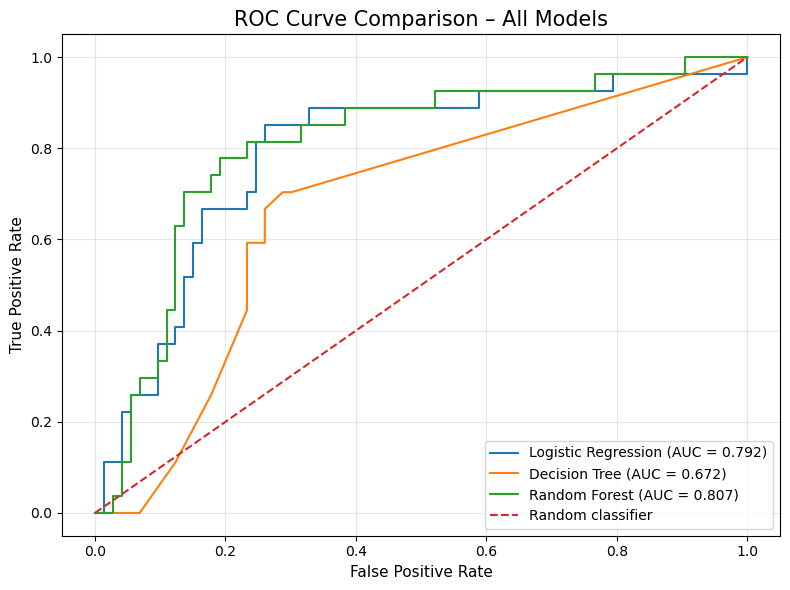

Top 12 factors – Logistic Regression


Feature,Logistic Regression Coefficient
categorical__InternetService_Fiber optic,0.931
categorical__Contract_One year,-0.918
categorical__InternetService_DSL,-0.732
numeric__SeniorCitizen,0.549
categorical__Contract_Two year,0.526
categorical__PaymentMethod_Credit card (automatic),-0.525
numeric__tenure,-0.499
numeric__MonthlyCharges,0.414
categorical__PaymentMethod_Mailed check,0.411
categorical__Contract_Month-to-month,0.391


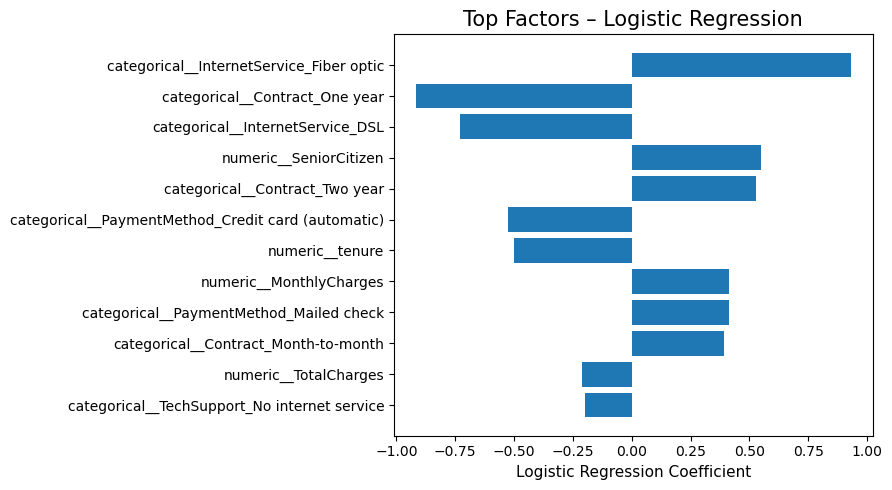

Top 12 factors – Decision Tree


Feature,Feature Importance
categorical__InternetService_Fiber optic,0.445
numeric__TotalCharges,0.355
categorical__OnlineSecurity_Yes,0.043
categorical__PaperlessBilling_No,0.042
numeric__tenure,0.040
categorical__TechSupport_No,0.029
categorical__Contract_Two year,0.026
numeric__MonthlyCharges,0.014
categorical__OnlineSecurity_No,0.004
categorical__OnlineBackup_No,0.000


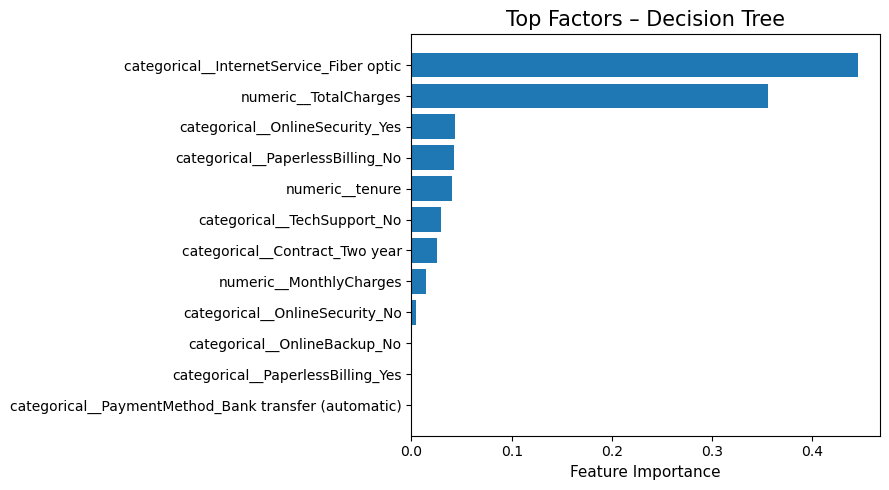

Top 12 factors – Random Forest


Feature,Feature Importance
numeric__MonthlyCharges,0.166
categorical__InternetService_Fiber optic,0.134
numeric__tenure,0.102
numeric__TotalCharges,0.098
categorical__Contract_Month-to-month,0.067
categorical__InternetService_DSL,0.048
categorical__TechSupport_No,0.043
numeric__SeniorCitizen,0.034
categorical__OnlineSecurity_No,0.033
categorical__Contract_One year,0.032


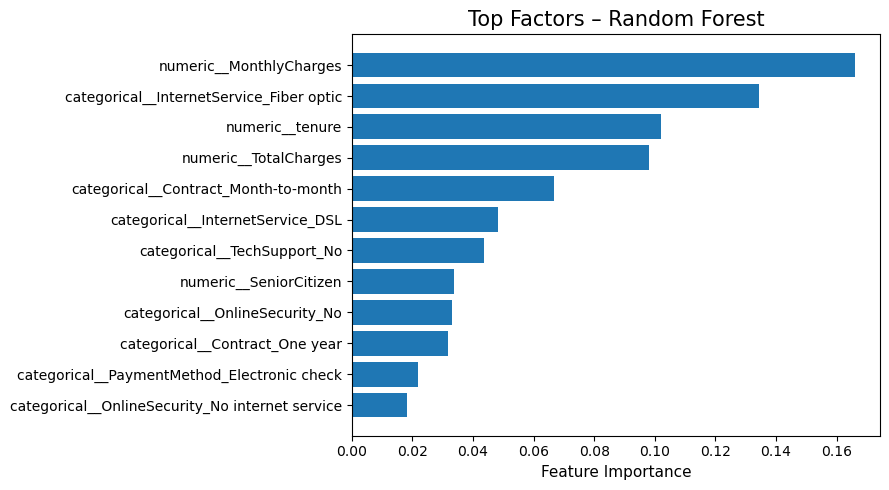

Top model by F1-score: Random Forest
               precision    recall  f1-score   support

  Stayed (No)       0.88      0.82      0.85        73
Churned (Yes)       0.59      0.70      0.64        27

     accuracy                           0.79       100
    macro avg       0.74      0.76      0.75       100
 weighted avg       0.80      0.79      0.80       100

Evaluation uses out-of-fold predictions from 5-fold stratified cross-validation. Feature importance is explanatory, not proof of causation.


In [11]:
# 11. Model Evaluation and Comparison

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=5, class_weight="balanced", random_state=42)
}

evaluation_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
evaluation_rows = []
oof_predictions = {}

for model_name, classifier in models.items():
    evaluation_pipeline = Pipeline([("preprocessing", preprocessor), ("classifier", classifier)])
    predicted_labels = cross_val_predict(evaluation_pipeline, X, y, cv=evaluation_cv, method="predict")
    predicted_probabilities = cross_val_predict(evaluation_pipeline, X, y, cv=evaluation_cv, method="predict_proba")[:, 1]
    oof_predictions[model_name] = {"labels": predicted_labels, "probabilities": predicted_probabilities}
    evaluation_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y, predicted_labels),
        "Precision": precision_score(y, predicted_labels, zero_division=0),
        "Recall": recall_score(y, predicted_labels, zero_division=0),
        "F1_Score": f1_score(y, predicted_labels, zero_division=0),
        "ROC_AUC": roc_auc_score(y, predicted_probabilities)
    })

evaluation_results = pd.DataFrame(evaluation_rows).sort_values("F1_Score", ascending=False).reset_index(drop=True)
print("MODEL COMPARISON – 5-FOLD CROSS-VALIDATION")
display(HTML(evaluation_results.round(3).to_html(index=False)))

# Compare all key evaluation metrics.
metric_columns = ["Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC"]
ax = evaluation_results.set_index("Model")[metric_columns].plot(kind="bar", figsize=(11, 6), ylim=(0, 1), edgecolor="black")
ax.set_title("Model Performance Comparison")
ax.set_xlabel("Machine Learning Model")
ax.set_ylabel("Cross-Validation Score")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

# Confusion matrix for EACH model using out-of-fold predictions.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (model_name, values) in zip(axes, oof_predictions.items()):
    cm = confusion_matrix(y, values["labels"], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(model_name)
plt.suptitle("Confusion Matrix Comparison – All Models")
plt.tight_layout(); plt.show()

# ROC curves for all models using out-of-fold probabilities.
plt.figure(figsize=(8, 6))
for model_name, values in oof_predictions.items():
    fpr, tpr, _ = roc_curve(y, values["probabilities"])
    auc_value = roc_auc_score(y, values["probabilities"])
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc_value:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison – All Models"); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# Feature importance / coefficient analysis using models fitted on the full sample.
# Logistic Regression coefficients show direction and magnitude; tree models show impurity-based importance.
feature_analysis = {}
for model_name, classifier in models.items():
    fitted_pipeline = Pipeline([("preprocessing", preprocessor), ("classifier", classifier)])
    fitted_pipeline.fit(X, y)
    feature_names = fitted_pipeline.named_steps["preprocessing"].get_feature_names_out()
    fitted_classifier = fitted_pipeline.named_steps["classifier"]
    if model_name == "Logistic Regression":
        values = fitted_classifier.coef_[0]
        label = "Logistic Regression Coefficient"
    else:
        values = fitted_classifier.feature_importances_
        label = "Feature Importance"
    feature_analysis[model_name] = pd.DataFrame({"Feature": feature_names, label: values})

for model_name, importance_df in feature_analysis.items():
    value_col = importance_df.columns[1]
    importance_df = importance_df.assign(Absolute_Value=importance_df[value_col].abs()).sort_values("Absolute_Value", ascending=False).head(12)
    print(f"Top 12 factors – {model_name}")
    display(HTML(importance_df.drop(columns="Absolute_Value").round(3).to_html(index=False)))
    plot_df = importance_df.sort_values("Absolute_Value")
    plt.figure(figsize=(9, 5))
    plt.barh(plot_df["Feature"], plot_df[value_col])
    plt.xlabel(value_col); plt.title(f"Top Factors – {model_name}")
    plt.tight_layout(); plt.show()

# Classification report for the model ranked highest by F1-score.
best_model_name = evaluation_results.loc[0, "Model"]
best_predictions = oof_predictions[best_model_name]["labels"]
print("Top model by F1-score:", best_model_name)
print(classification_report(y, best_predictions, target_names=["Stayed (No)", "Churned (Yes)"], zero_division=0))
print("Evaluation uses out-of-fold predictions from 5-fold stratified cross-validation. Feature importance is explanatory, not proof of causation.")


## 12. Interactive Streamlit Application

Run `streamlit run app.py` from this project folder to open an interactive interface. The app accepts an individual customer profile, displays predicted churn probability, risk level and tailored retention actions, and provides CSV downloads for both the individual prediction and the full 100-customer retention report.


## 13. Conclusion

This project demonstrates customer churn prediction, risk segmentation, personalized retention recommendations, exploratory visualizations, and cross-validated comparison of Logistic Regression, Decision Tree, and Random Forest. It also includes confusion matrices for all models, ROC curves, and feature coefficient/importance analysis. The companion Streamlit application supports individual customer predictions and downloadable retention reports. Results are educational and based on a small 100-record sample; validate on a larger, representative dataset before any real business deployment. Offers are illustrative and require business approval.
